# Phase 1 – Data Understanding & Quality Checks
**Sigmoid case study – Bike Sharing Demand**



## Step 1 – Upload the dataset

In [ ]:
import os
import pandas as pd

# Check uploaded files
print(os.listdir("."))

# Read CSV files directly
hour_df = pd.read_csv("hour.csv")
day_df = pd.read_csv("day.csv")

# Display available files
print("Files loaded successfully!")

print("Hourly Dataset:", hour_df.shape)
print("Daily Dataset:", day_df.shape)

display(hour_df.head())
display(day_df.head())

['.config', 'Readme.txt', 'day.csv', 'hour.csv', 'sample_data']
Files loaded successfully!
Hourly Dataset: (17379, 17)
Daily Dataset: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
readme = open("Readme.txt", encoding="latin-1").read()

start = readme.find("Dataset characteristics")
end = readme.find("License")

print(readme[start:end])

Dataset characteristics
Both hour.csv and day.csv have the following fields, except hr which is not available in day.csv
	
	- instant: record index
	- dteday : date
	- season : season (1:springer, 2:summer, 3:fall, 4:winter)
	- yr : year (0: 2011, 1:2012)
	- mnth : month ( 1 to 12)
	- hr : hour (0 to 23)
	- holiday : weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)
	- weekday : day of the week
	- workingday : if day is neither weekend nor holiday is 1, otherwise is 0.
	+ weathersit : 
		- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
		- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
		- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
		- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
	- temp : Normalized temperature in Celsius. The values are divided to 41 (max)
	- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max)
	- hum: Normalized 

## Step 3 – Load data, shape and data types

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

hour = pd.read_csv("hour.csv", parse_dates=["dteday"])
day = pd.read_csv("day.csv", parse_dates=["dteday"])

print("hour.csv:", hour.shape, "| day.csv:", day.shape)

display(hour.head())
print(hour.dtypes)

hour.csv: (17379, 17) | day.csv: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object


**Expected:** `hour.csv: (17379, 17) | day.csv: (731, 16)`. All columns numeric except `dteday` (date).

## Step 4 – Missing values and duplicates

In [ ]:
for name, df in [("hour", hour), ("day", day)]:
    print(f"{name}: nulls = {df.isna().sum().sum()}, "
          f"duplicate rows = {df.duplicated().sum()}, "
          f"duplicates ignoring 'instant' = {df.drop(columns='instant').duplicated().sum()}")

hour: nulls = 0, duplicate rows = 0, duplicates ignoring 'instant' = 0
day: nulls = 0, duplicate rows = 0, duplicates ignoring 'instant' = 0


## Step 5 – Consistency checks (leakage + hourly vs daily)

In [ ]:
print("hour: cnt == casual + registered on every row ->", (hour.cnt == hour.casual + hour.registered).all())
print("day : cnt == casual + registered on every row ->", (day.cnt == day.casual + day.registered).all())

hourly_sum = hour.groupby("dteday").cnt.sum()
print("hourly totals equal daily file for all days  ->", (hourly_sum.values == day.set_index("dteday").cnt.values).all())

hour: cnt == casual + registered on every row -> True
day : cnt == casual + registered on every row -> True
hourly totals equal daily file for all days  -> True


## Step 6 – Valid ranges for every column

In [ ]:
checks = {
    "season in 1-4":      hour.season.between(1, 4).all(),
    "yr in 0-1":          hour.yr.isin([0, 1]).all(),
    "mnth in 1-12":       hour.mnth.between(1, 12).all(),
    "hr in 0-23":         hour.hr.between(0, 23).all(),
    "weekday in 0-6":     hour.weekday.between(0, 6).all(),
    "holiday/workingday binary": hour.holiday.isin([0,1]).all() and hour.workingday.isin([0,1]).all(),
    "weathersit in 1-4":  hour.weathersit.between(1, 4).all(),
    "temp/atemp/hum/wind in [0,1]": hour[["temp","atemp","hum","windspeed"]].apply(lambda c: c.between(0,1).all()).all(),
    "counts non-negative": (hour[["casual","registered","cnt"]] >= 0).all().all(),
}
for k, v in checks.items():
    print(f"{k:32s} {v}")

display(hour.drop(columns=["instant", "dteday"]).describe().T[["min", "max", "mean"]].round(3))

season in 1-4                    True
yr in 0-1                        True
mnth in 1-12                     True
hr in 0-23                       True
weekday in 0-6                   True
holiday/workingday binary        True
weathersit in 1-4                True
temp/atemp/hum/wind in [0,1]     True
counts non-negative              True


,min,max,mean
season,1.00,4.000,2.502
yr,0.00,1.000,0.503
mnth,1.00,12.000,6.538
hr,0.00,23.000,11.547
holiday,0.00,1.000,0.029
weekday,0.00,6.000,3.004
workingday,0.00,1.000,0.683
weathersit,1.00,4.000,1.425
temp,0.02,1.000,0.497
atemp,0.00,1.000,0.476


## Step 7 – Date coverage and missing hours

In [ ]:
print("Date range:", hour.dteday.min().date(), "to", hour.dteday.max().date(), "| days:", hour.dteday.nunique())
print("Expected hours:", hour.dteday.nunique() * 24, "| present:", len(hour),
      "| missing:", hour.dteday.nunique() * 24 - len(hour))

hours_per_day = hour.groupby("dteday").size()
print("\nDays by number of recorded hours:\n", hours_per_day.value_counts().sort_index())
print("\nDays with fewer than 22 hours:\n", hours_per_day[hours_per_day < 22])

# Which clock hours are missing on ordinary days?
full = pd.MultiIndex.from_product([hours_per_day.index, range(24)], names=["dteday", "hr"])
missing = full.difference(pd.MultiIndex.from_frame(hour[["dteday", "hr"]])).to_frame(index=False)
storm_days = hours_per_day[hours_per_day < 22].index
print("\nMissing hours by clock hour (storm days excluded):")
print(missing[~missing.dteday.isin(storm_days)].hr.value_counts().sort_index().to_dict())
print("\nSmallest cnt in the file:", hour.cnt.min())

Date range: 2011-01-01 to 2012-12-31 | days: 731
Expected hours: 17544 | present: 17379 | missing: 165

Days by number of recorded hours:
 1       1
8       1
11      1
12      1
16      1
17      1
18      2
22      6
23     62
24    655
Name: count, dtype: int64

Days with fewer than 22 hours:
 dteday
2011-01-18    12
2011-01-26    16
2011-01-27     8
2011-02-22    18
2011-08-27    18
2011-08-28    17
2012-10-29     1
2012-10-30    11
dtype: int64

Missing hours by clock hour (storm days excluded):
{1: 1, 2: 10, 3: 27, 4: 27, 5: 8, 6: 1}

Smallest cnt in the file: 1


## Step 8 – Implausible values (in range but physically wrong)

In [ ]:
print("Rows with humidity = 0:", (hour.hum == 0).sum(), "on dates", hour.loc[hour.hum == 0, "dteday"].dt.date.unique())
print("Rows with windspeed = 0:", (hour.windspeed == 0).sum(),
      f"({(hour.windspeed == 0).mean():.1%})")
print("Smallest windspeed values:", sorted(hour.windspeed.unique())[:4])
print("\nweathersit counts:\n", hour.weathersit.value_counts().sort_index())

Rows with humidity = 0: 22 on dates [datetime.date(2011, 3, 10)]
Rows with windspeed = 0: 2180 (12.5%)
Smallest windspeed values: [np.float64(0.0), np.float64(0.0896), np.float64(0.1045), np.float64(0.1343)]

weathersit counts:
 weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


## Step 9 – Confirm the weekday coding

In [ ]:
first = hour.iloc[0]
print(first.dteday.date(), "is a", first.dteday.day_name(), "-> weekday code", first.weekday)

# workingday should be 1 exactly when it is Mon-Fri and not a holiday
derived = ((hour.weekday.between(1, 5)) & (hour.holiday == 0)).astype(int)
print("workingday matches (Mon-Fri & not holiday):", (derived == hour.workingday).all())

2011-01-01 is a Saturday -> weekday code 6
workingday matches (Mon-Fri & not holiday): True


## Step 10 – Target distribution (outliers?)

count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64
Skewness: 1.28
Quantiles: {0.5: 142.0, 0.9: 451.0, 0.99: 782.0}


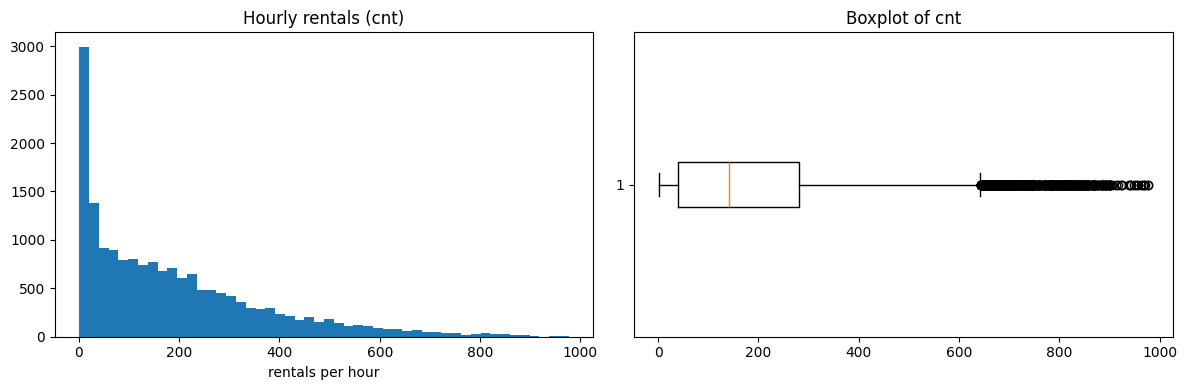

IQR outliers (> 642): 505 rows
Share on working days: 0.82
Most common hours: {17: 153, 18: 129, 8: 127, 13: 23}


In [ ]:
print(hour.cnt.describe().round(1))
print("Skewness:", round(hour.cnt.skew(), 2))
print("Quantiles:", hour.cnt.quantile([0.5, 0.9, 0.99]).round(0).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(hour.cnt, bins=50); ax[0].set_title("Hourly rentals (cnt)"); ax[0].set_xlabel("rentals per hour")
ax[1].boxplot(hour.cnt, vert=False); ax[1].set_title("Boxplot of cnt")
plt.tight_layout(); plt.show()

# Where do the 'outliers' happen?
q1, q3 = hour.cnt.quantile([0.25, 0.75]); upper = q3 + 1.5 * (q3 - q1)
out = hour[hour.cnt > upper]
print(f"IQR outliers (> {upper:.0f}): {len(out)} rows")
print("Share on working days:", round(out.workingday.mean(), 2))
print("Most common hours:", out.hr.value_counts().head(4).to_dict())

## Step 11 – Year-on-year growth (affects how we split train/test)

yr
2011    143.8
2012    234.7
Name: cnt, dtype: float64
Growth: +63%


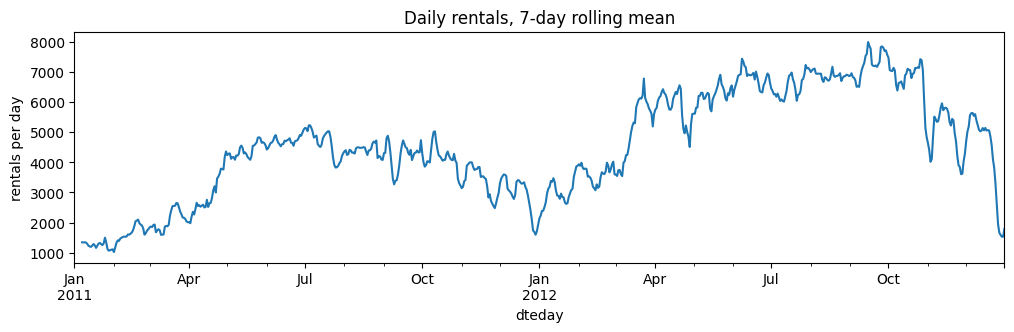

In [ ]:
print(hour.groupby("yr").cnt.mean().rename({0: "2011", 1: "2012"}).round(1))
growth = hour[hour.yr == 1].cnt.mean() / hour[hour.yr == 0].cnt.mean() - 1
print(f"Growth: {growth:+.0%}")

day.set_index("dteday").cnt.rolling(7).mean().plot(figsize=(12, 3), title="Daily rentals, 7-day rolling mean")
plt.ylabel("rentals per day"); plt.show()

## Step 12 – The key early signal: working vs non-working hourly pattern

    Non-working day  Working day
hr                              
3              26.0          5.0
8             106.0        477.0
12            366.0        201.0
17            324.0        525.0
18            281.0        492.0


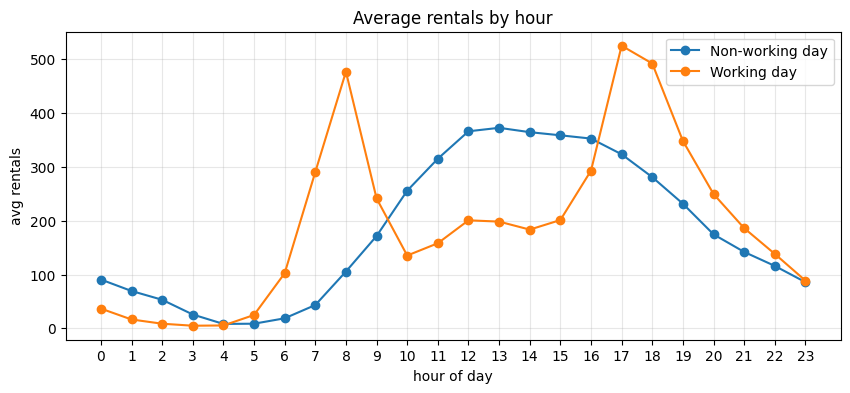

In [ ]:
profile = hour.groupby(["hr", "workingday"]).cnt.mean().unstack()
profile.columns = ["Non-working day", "Working day"]
print(profile.loc[[3, 8, 12, 17, 18]].round(0))

profile.plot(figsize=(10, 4), marker="o", title="Average rentals by hour")
plt.xlabel("hour of day"); plt.ylabel("avg rentals"); plt.xticks(range(24)); plt.grid(alpha=.3); plt.show()

## Step 13 – Quick sanity check on daily totals (formal test comes in Phase 2)

In [ ]:
from scipy import stats
wd, nwd = day.cnt[day.workingday == 1], day.cnt[day.workingday == 0]
print(f"Working days: n={len(wd)}, mean={wd.mean():.0f} | Non-working: n={len(nwd)}, mean={nwd.mean():.0f}")
print(stats.ttest_ind(wd, nwd, equal_var=False))

Working days: n=500, mean=4585 | Non-working: n=231, mean=4330
TtestResult(statistic=np.float64(1.6013720686967898), pvalue=np.float64(0.11005737827017054), df=np.float64(413.93578279295593))


## Phase 1 summary –

---


| Check | Result |
|---|---|
| Nulls / duplicates | none |
| Leakage | `casual + registered = cnt` → excluded; `instant` excluded |
| Missing hours | 165 (mostly zero-demand night hours + storm shutdowns) |
| Bad values | `hum=0` on 2011-03-10 (impute), `windspeed=0` 12.5% (flag), `weathersit=4` ×3 (merge) |
| Outliers | genuine commute peaks → kept |
| Trend | +63% growth 2011→2012 → affects train/test split |
| Key insight | similar daily volume, very different hourly timing |